# 01 — Audit Data dan Split

Notebook ini adalah tahap pertama pipeline: mengekstrak dataset, mengaudit isinya, dan melihat contoh citra tiap kelas.

**Status:** bagian ekstraksi, audit, dan visualisasi sudah dikerjakan. Bagian cek duplikat (dHash) dan split group-aware **belum dikerjakan** (lihat placeholder di akhir).

Dataset: *Batik Kawung, Megamendung, Parang, Sekarjagad, and Truntum Image Dataset* (Putra & Zamzami, Mendeley Data, 2025, CC BY 4.0).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from project import config

config.ensure_dirs()
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
rng = np.random.default_rng(config.SEED)

## 1. Ekstraksi dataset

File ZIP dari Mendeley berisi ZIP lain di dalamnya (`Batik Motif Dataset/<Kelas>/*.jpg`). Fungsi `extract_dataset()` membuka kedua lapis ZIP dan menyalin citra ke `data/raw/<Kelas>/` tanpa mengubah nama file. ZIP asli di `dataset/` tidak disentuh. Kalau `data/raw/` sudah berisi citra, ekstraksi dilewati.

In [2]:
from project.data import extract_dataset, build_index, audit_images

extract_dataset();

Dataset already extracted in data\raw


## 2. Indeks citra dan jumlah per kelas

Label diambil dari nama folder dan dinormalisasi secara *case-insensitive* (`Kawung`, `Batik Kawung` → `kawung`). Eksperimen utama hanya memakai 3 kelas (Kawung, Megamendung, Parang); dua kelas lain tetap ditampilkan di sini sebagai gambaran dataset lengkap.

In [3]:
df_all = build_index()
counts = df_all["label"].value_counts().reindex(config.ALL_CLASSES)
summary = pd.DataFrame({
    "jumlah": counts,
    "persen": (counts / counts.sum() * 100).round(1),
    "dipakai_utama": ["ya" if c in config.MAIN_CLASSES else "tidak" for c in counts.index],
})
summary.loc["TOTAL"] = [counts.sum(), 100.0, ""]
summary

,jumlah,persen,dipakai_utama
label,,,
kawung,626,25.6,ya
megamendung,390,15.9,ya
parang,804,32.8,ya
sekarjagad,339,13.8,tidak
truntum,289,11.8,tidak
TOTAL,2448,100.0,


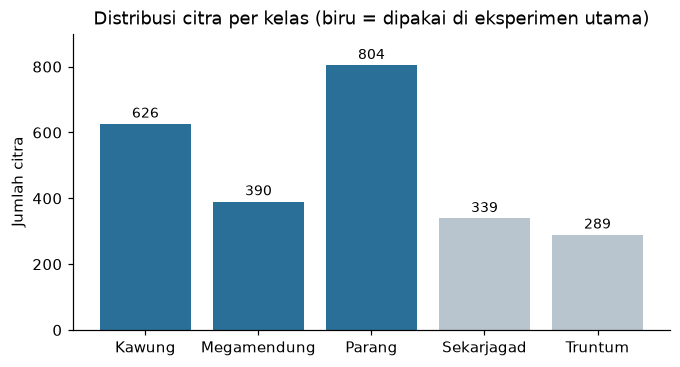

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
colors = ["#2a6f97" if c in config.MAIN_CLASSES else "#b8c4ce" for c in counts.index]
bars = ax.bar([c.capitalize() for c in counts.index], counts.values, color=colors)
ax.bar_label(bars, padding=2, fontsize=9)
ax.set_ylabel("Jumlah citra")
ax.set_title("Distribusi citra per kelas (biru = dipakai di eksperimen utama)")
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, counts.max() * 1.12)
fig.savefig(config.FIGURES_DIR / "01_distribusi_kelas.png")
plt.show()

Data tidak seimbang: di 3 kelas utama, Parang hampir 2× Megamendung. Karena itu, sesuai desain, semua citra tetap dipakai, split dibuat *stratified*, SVM memakai `class_weight='balanced'`, dan model dipilih berdasarkan F1 makro, bukan akurasi.

## 3. Audit file: citra rusak, ukuran, mode warna

Setiap citra dibuka dan di-*decode* penuh. Yang dicek:
- **file rusak** (gagal dibaca atau terpotong),
- **ukuran** — preprocessing mengasumsikan 224×224 dan *tidak* melakukan resize; citra dengan ukuran lain harus dilaporkan,
- **mode warna** — RGBA/palette/grayscale nantinya dikonversi ke RGB.

Audit dijalankan di dataset lengkap (5 kelas) karena murah dan tidak memengaruhi keputusan model.

In [5]:
audit = audit_images(df_all)
print("Citra gagal dibaca :", (~audit["ok"]).sum())
audit[audit["ok"]].groupby(["width", "height", "mode"]).size().rename("jumlah").to_frame()

Audit:   0%|          | 0/2448 [00:00<?, ?it/s]

Citra gagal dibaca : 0


,,,jumlah
width,height,mode,
224,224,RGB,2448


In [6]:
bad = audit[~audit["ok"]]
not_224 = audit[audit["ok"] & ((audit["width"] != config.IMAGE_SIZE) | (audit["height"] != config.IMAGE_SIZE))]
not_rgb = audit[audit["ok"] & (audit["mode"] != "RGB")]
print(f"Bukan {config.IMAGE_SIZE}x{config.IMAGE_SIZE}: {len(not_224)}  | bukan RGB: {len(not_rgb)}  | rusak: {len(bad)}")
audit.to_csv(config.RESULTS_DIR / "audit.csv", index=False)
bad.head()

Bukan 224x224: 0  | bukan RGB: 0  | rusak: 0


,filepath,filename,folder,label,ok,width,height,mode,error


## 4. Contoh citra per kelas

Enam citra acak (seed 42) dari tiap kelas utama. Tujuannya melihat variasi intra-kelas (warna, skala motif, orientasi) yang nantinya harus ditangkap oleh fitur tekstur. Sampel diambil dari seluruh data karena split belum dibuat; ini hanya untuk inspeksi visual, bukan untuk keputusan model.

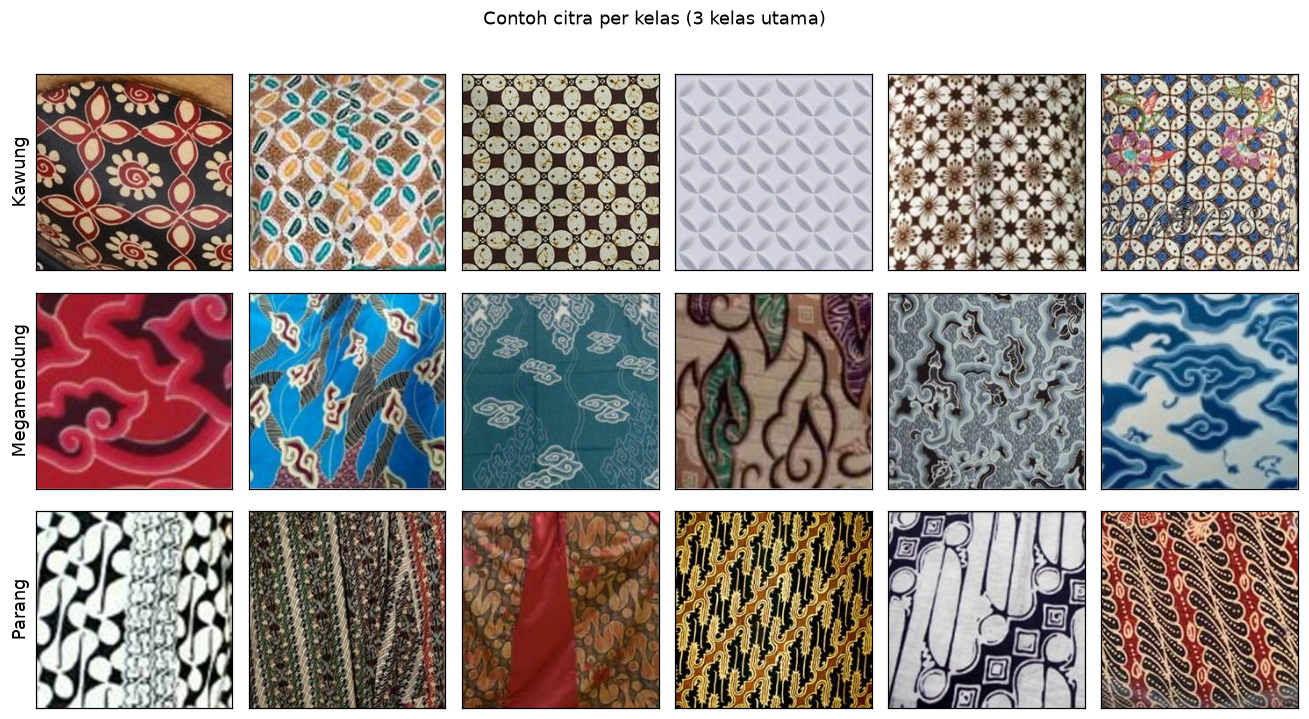

In [7]:
from PIL import Image

df = df_all[df_all["label"].isin(config.MAIN_CLASSES)].reset_index(drop=True)
n_per_class = 6
fig, axes = plt.subplots(len(config.MAIN_CLASSES), n_per_class, figsize=(2 * n_per_class, 2.2 * len(config.MAIN_CLASSES)))
for r, cls in enumerate(config.MAIN_CLASSES):
    paths = df[df["label"] == cls].sample(n_per_class, random_state=config.SEED)["filepath"]
    for c, fp in enumerate(paths):
        ax = axes[r, c]
        ax.imshow(Image.open(config.ROOT / fp).convert("RGB"))
        ax.set_xticks([]); ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(cls.capitalize(), fontsize=12)
fig.suptitle("Contoh citra per kelas (3 kelas utama)", y=1.0)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "01_contoh_citra.png")
plt.show()

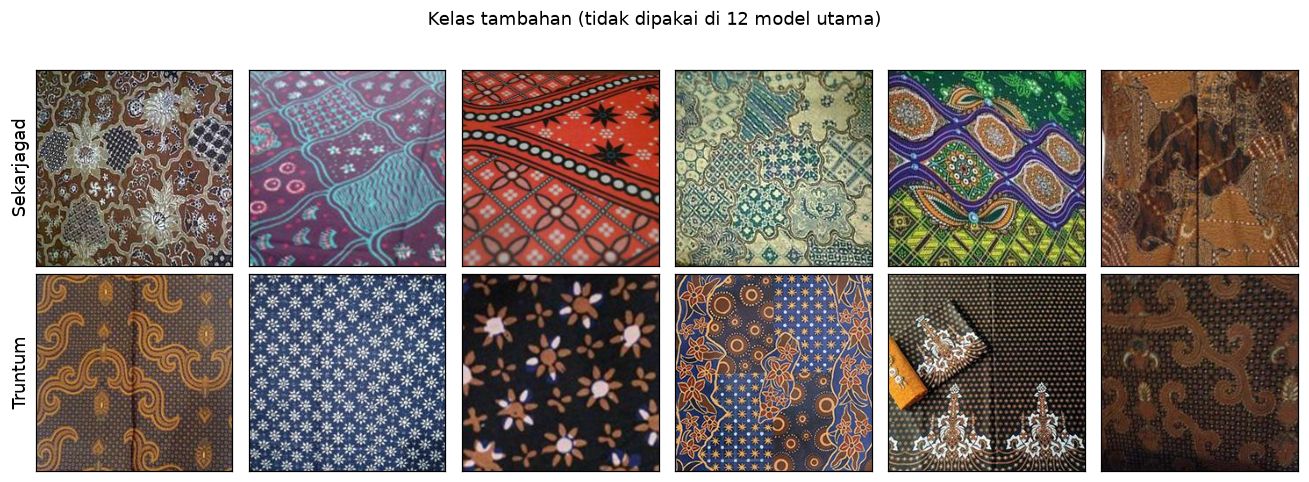

In [8]:
others = [c for c in config.ALL_CLASSES if c not in config.MAIN_CLASSES]
fig, axes = plt.subplots(len(others), n_per_class, figsize=(2 * n_per_class, 2.2 * len(others)))
for r, cls in enumerate(others):
    paths = df_all[df_all["label"] == cls].sample(n_per_class, random_state=config.SEED)["filepath"]
    for c, fp in enumerate(paths):
        ax = axes[r, c]
        ax.imshow(Image.open(config.ROOT / fp).convert("RGB"))
        ax.set_xticks([]); ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(cls.capitalize(), fontsize=12)
fig.suptitle("Kelas tambahan (tidak dipakai di 12 model utama)", y=1.0)
fig.tight_layout()
plt.show()

## 5. Cek duplikat / near-duplicate (dHash) — *belum dikerjakan*

> **Placeholder.** Rencana: dHash 64-bit (numpy + PIL), citra dengan jarak Hamming ≤ 5 digabung ke satu `group_id`, lalu dilaporkan jumlah grup duplikat.

## 6. Split train/test group-aware — *belum dikerjakan*

> **Placeholder.** Rencana: 80/20, stratified per kelas, group-aware (satu grup duplikat tidak terbelah), `random_state=42`, disimpan ke `results/split.csv`.